In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

PATH = '/homedir/'

customers   = pd.read_csv(PATH + 'olist_customers_dataset.csv')
orders      = pd.read_csv(PATH + 'olist_orders_dataset.csv')
order_items = pd.read_csv(PATH + 'olist_order_items_dataset.csv')

print(f'customers:   {customers.shape}')
print(f'orders:      {orders.shape}')
print(f'order_items: {order_items.shape}')

customers:   (99441, 5)
orders:      (99441, 8)
order_items: (112650, 7)


In [ ]:
# После загрузки трёх таблиц я заметил, что в customers и orders одинаковое количество строк — 99 441. Это означает, что customer_id создаётся для каждого заказа. Чтобы отслеживать одного и того же клиента, дальше я буду использовать customer_unique_id.

In [2]:
print(orders.head())
print()
print('статусы заказов:')
print(orders['order_status'].value_counts())

                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49  2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06  2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39  2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26 14:31:00           2018-08

In [ ]:
# Посмотрел, какие статусы есть у заказов. Большая часть заказов была успешно доставлена 96478 из 99441 поэтому дальше работаю только с заказами со статусом delivered. Они лучше всего подходят для анализа поведения и опыта клиентов.

In [3]:
print(orders.isnull().sum())

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [ ]:
# Проверил пропуски в данных. Они есть только в датах доставки, и это нормально. Дальше я работаю только с доставленными заказами, поэтому на анализ это не повлияет.

In [5]:
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])

orders_delivered = orders[orders['order_status'] == 'delivered'].copy()
print('доставленных заказов:', len(orders_delivered))

orders_full = orders_delivered.merge(
    customers[['customer_id', 'customer_unique_id']],
    on='customer_id'
)
print('уникальных клиентов:', orders_full['customer_unique_id'].nunique())

доставленных заказов: 96478
уникальных клиентов: 93358


In [ ]:
# Оставил только доставленные заказы и добавил уникальный идентификатор клиента. Получилось 93 358 клиентов на 96 478 заказов, значит часть клиентов покупала больше одного раза.

In [6]:
orders_full['order_month'] = orders_full['order_purchase_timestamp'].dt.to_period('M')

first_orders = orders_full.groupby('customer_unique_id')['order_month'].min()
first_orders = first_orders.reset_index()
first_orders.columns = ['customer_unique_id', 'cohort_month']

orders_full = orders_full.merge(first_orders, on='customer_unique_id')

orders_full['period'] = (
    orders_full['order_month'].astype('int64') - 
    orders_full['cohort_month'].astype('int64')
)

print(orders_full[['customer_unique_id', 'order_month', 'cohort_month', 'period']].head())

                 customer_unique_id order_month cohort_month  period
0  7c396fd4830fd04220f754e42b4e5bff     2017-10      2017-09       1
1  7c396fd4830fd04220f754e42b4e5bff     2017-09      2017-09       0
2  af07308b275d755c9edb36a90c618231     2018-07      2018-07       0
3  3a653a41f6f9fc3d2a113cf8398680e8     2018-08      2018-08       0
4  7c142cf63193a1473d2e66489a9ae977     2017-11      2017-11       0


In [ ]:
# Для каждого клиента определил месяц первой покупки и сформировал когорты. После этого посчитал, сколько месяцев прошло с первого заказа. Максимальный период 20 месяцев, значит данных достаточно для анализа удержания клиентов почти за 2 года.

In [7]:
cohort_data = orders_full.groupby(['cohort_month', 'period'])['customer_unique_id'].nunique()
cohort_data = cohort_data.reset_index()
cohort_data.columns = ['cohort_month', 'period', 'n_customers']

cohort_sizes = cohort_data[cohort_data['period'] == 0][['cohort_month', 'n_customers']]
cohort_sizes.columns = ['cohort_month', 'cohort_size']

cohort_data = cohort_data.merge(cohort_sizes, on='cohort_month')

cohort_data['retention'] = cohort_data['n_customers'] / cohort_data['cohort_size'] * 100

avg_retention = cohort_data.groupby('period')['retention'].mean()
print(avg_retention.round(2))

period
0     100.00
1       5.45
2       0.34
3       0.25
4       0.29
5       0.23
6       0.27
7       0.21
8       0.21
9       0.19
10      0.26
11      0.23
12      0.21
13      0.20
14      0.15
15      0.19
16      0.14
17      0.28
19      0.45
20      0.76
Name: retention, dtype: float64


In [ ]:
# Посчитал размер каждой когорты и рассчитал retention для каждого периода. В среднем в первый месяц возвращается 5,45% клиентов. В последующие месяцы показатель постепенно снижается и к концу периода достигает примерно 0,3%. Это говорит о низком уровне повторных покупок и слабом удержании клиентов.

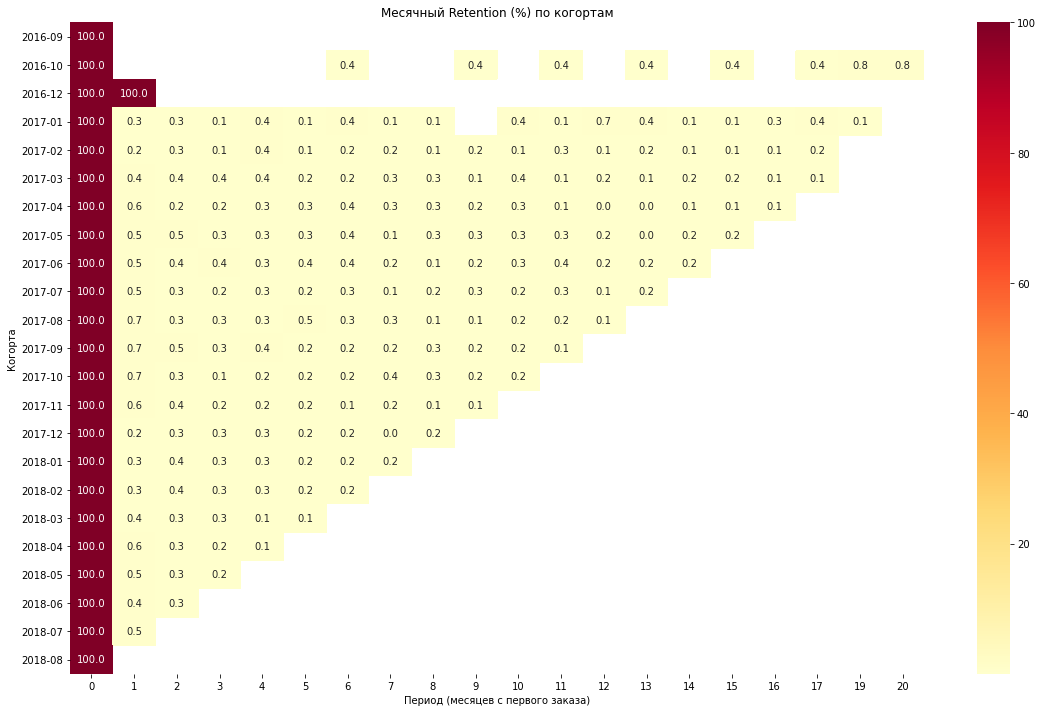

In [8]:
retention_matrix = cohort_data.pivot_table(
    index='cohort_month',
    columns='period',
    values='retention'
)

plt.figure(figsize=(16, 10))
sns.heatmap(retention_matrix, annot=True, fmt='.1f', cmap='YlOrRd')
plt.title('Месячный Retention (%) по когортам')
plt.xlabel('Период (месяцев с первого заказа)')
plt.ylabel('Когорта')
plt.tight_layout()
plt.savefig('retention_heatmap.png', dpi=150)
plt.show()

In [ ]:
# Построил тепловую карту retention, чтобы наглядно посмотреть, как меняется удержание клиентов по когортам с течением времени.

всего клиентов: 93,358
с 1 заказом: 91,665
с >1 заказом: 1,693 (1.8%)


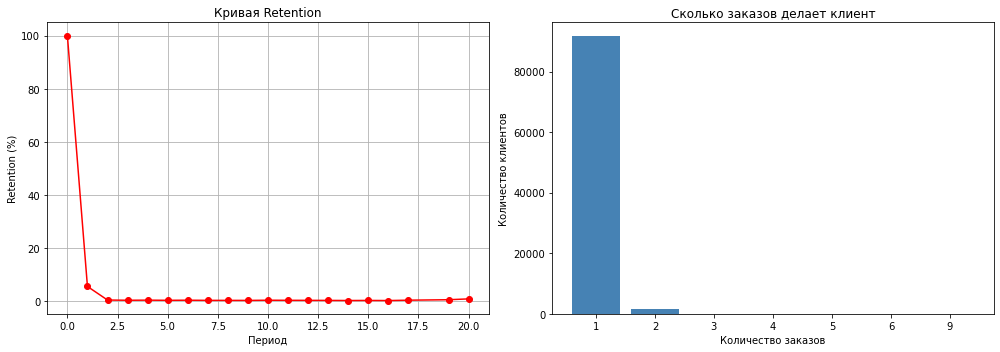

In [9]:
orders_per_customer = orders_full.groupby('customer_unique_id')['order_month'].nunique()

repeat_customers = (orders_per_customer > 1).sum()
total_customers = len(orders_per_customer)
pct_repeat = repeat_customers / total_customers * 100

print(f'всего клиентов: {total_customers:,}')
print(f'с 1 заказом: {(orders_per_customer == 1).sum():,}')
print(f'с >1 заказом: {repeat_customers:,} ({pct_repeat:.1f}%)')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(avg_retention.index, avg_retention.values, marker='o', color='red')
axes[0].set_title('Кривая Retention')
axes[0].set_xlabel('Период')
axes[0].set_ylabel('Retention (%)')
axes[0].grid(True)

order_counts = orders_per_customer.value_counts().sort_index().head(8)
axes[1].bar(order_counts.index.astype(str), order_counts.values, color='steelblue')
axes[1].set_title('Сколько заказов делает клиент')
axes[1].set_xlabel('Количество заказов')
axes[1].set_ylabel('Количество клиентов')

plt.tight_layout()
plt.savefig('pmf_analysis.png', dpi=150)
plt.show()

In [ ]:
# Посчитал, сколько заказов приходится на каждого клиента, и построил графики распределения. Оказалось, что 98,2% клиентов совершили только один заказ. Это подтверждает результаты когортного анализа: большинство покупателей не возвращаются за повторной покупкой. Такая картина указывает на низкое удержание клиентов и может быть одной из причин замедления роста выручки.

средний чек: 137.04 BRL
всего заказов: 96,478
retention: 1.8%
общая выручка: 13,221,498 BRL


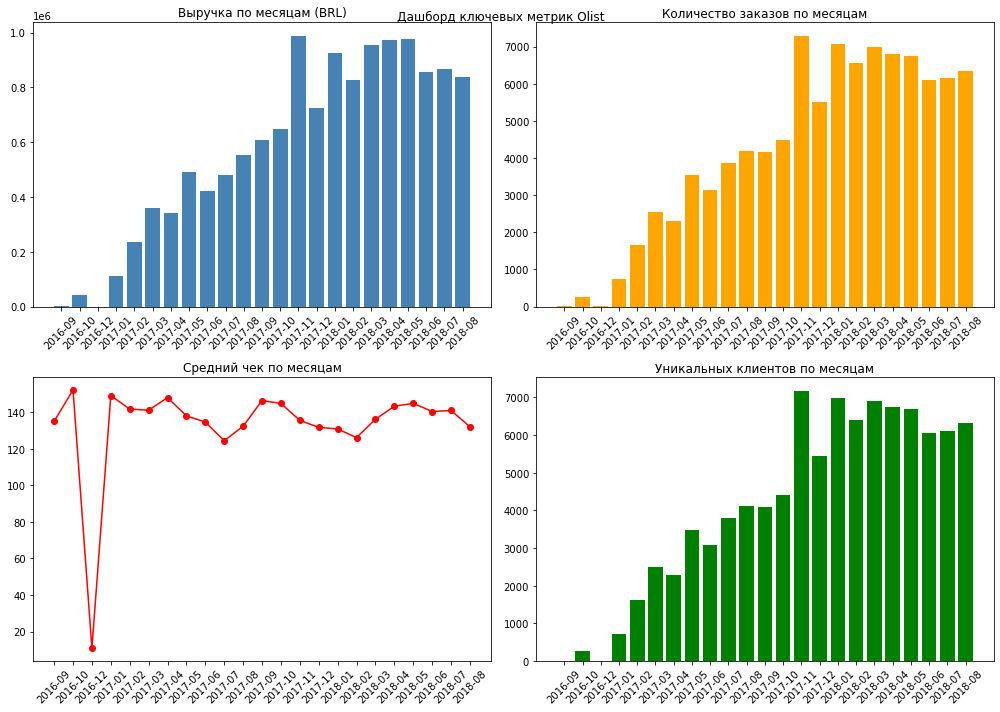

In [10]:
orders_items_full = orders_full.merge(
    order_items[['order_id', 'price', 'freight_value']],
    on='order_id'
)

revenue_by_month = orders_items_full.groupby('order_month').agg(
    revenue=('price', 'sum'),
    n_orders=('order_id', 'nunique'),
    n_customers=('customer_unique_id', 'nunique')
).reset_index()

revenue_by_month['avg_check'] = revenue_by_month['revenue'] / revenue_by_month['n_orders']
revenue_by_month['order_month'] = revenue_by_month['order_month'].astype(str)

avg_check = orders_items_full.groupby('order_id')['price'].sum().mean()
print(f'средний чек: {avg_check:.2f} BRL')
print(f'всего заказов: {orders_full["order_id"].nunique():,}')
print(f'retention: {pct_repeat:.1f}%')
print(f'общая выручка: {orders_items_full["price"].sum():,.0f} BRL')

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0,0].bar(revenue_by_month['order_month'], revenue_by_month['revenue'], color='steelblue')
axes[0,0].set_title('Выручка по месяцам (BRL)')
axes[0,0].tick_params(axis='x', rotation=45)

axes[0,1].bar(revenue_by_month['order_month'], revenue_by_month['n_orders'], color='orange')
axes[0,1].set_title('Количество заказов по месяцам')
axes[0,1].tick_params(axis='x', rotation=45)

axes[1,0].plot(revenue_by_month['order_month'], revenue_by_month['avg_check'], marker='o', color='red')
axes[1,0].set_title('Средний чек по месяцам')
axes[1,0].tick_params(axis='x', rotation=45)

axes[1,1].bar(revenue_by_month['order_month'], revenue_by_month['n_customers'], color='green')
axes[1,1].set_title('Уникальных клиентов по месяцам')
axes[1,1].tick_params(axis='x', rotation=45)

plt.suptitle('Дашборд ключевых метрик Olist')
plt.tight_layout()
plt.savefig('metrics_dashboard.png', dpi=150)
plt.show()

In [ ]:
# Присоединил стоимость товаров, рассчитал основные метрики по месяцам и собрал дашборд. По графикам видно, что выручка росла до конца 2017 начала 2018 года, после чего рост практически остановился. При этом средний чек оставался стабильным  около 137 BRL, значит проблема не в стоимости заказа. Также с середины 2018 года стало снижаться количество новых клиентов. В сочетании с низким retention это говорит о том, что существующие клиенты редко возвращаются за повторными покупками, а приток новых клиентов постепенно уменьшается.

                                            Гипотеза  Impact  Confidence  \
1  H2: Email/push через 30 дней после первого заказа       8           7   
0                            H1: Упростить онбординг       7           6   
2                           H3: Программа лояльности       6           4   

   Ease  ICE  
1     7  392  
0     8  336  
2     3   72  


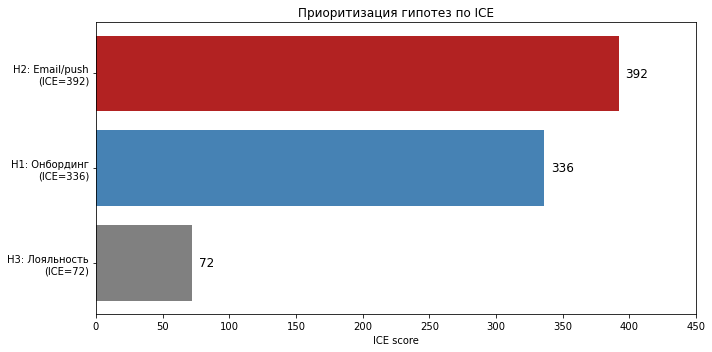

In [11]:
hypotheses = pd.DataFrame({
    'Гипотеза': [
        'H1: Упростить онбординг',
        'H2: Email/push через 30 дней после первого заказа',
        'H3: Программа лояльности'
    ],
    'Impact': [7, 8, 6],
    'Confidence': [6, 7, 4],
    'Ease': [8, 7, 3]
})

hypotheses['ICE'] = hypotheses['Impact'] * hypotheses['Confidence'] * hypotheses['Ease']
hypotheses = hypotheses.sort_values('ICE', ascending=False)
print(hypotheses)

fig, ax = plt.subplots(figsize=(10, 5))

labels = ['H3: Лояльность\n(ICE=72)', 'H1: Онбординг\n(ICE=336)', 'H2: Email/push\n(ICE=392)']
values = [72, 336, 392]
colors = ['gray', 'steelblue', 'firebrick']

bars = ax.barh(labels, values, color=colors)
for bar, val in zip(bars, values):
    ax.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2,
            str(val), va='center', fontsize=12)

ax.set_title('Приоритизация гипотез по ICE')
ax.set_xlabel('ICE score')
ax.set_xlim(0, 450)
plt.tight_layout()
plt.savefig('ice_chart.png', dpi=150)
plt.show()

In [ ]:
# Составил список гипотез, оценил каждую по методу ICE и визуализировал результаты. Наибольший балл получила гипотеза H2 (392), поэтому выбрал её для дальнейшей проверки. Она направлена на решение основной проблемы низкого retention, при этом относительно проста в реализации. Гипотеза H3 получила более низкую оценку из-за высокой сложности внедрения и большей неопределённости ожидаемого эффекта.

In [12]:
ret_period_1 = cohort_data[cohort_data['period'] == 1]['retention'].mean()
print(f'retention период 1: {ret_period_1:.2f}%')

repeat_orders = orders_full[orders_full['period'] > 0].copy()
first_order_dates = orders_full[orders_full['period'] == 0][['customer_unique_id', 'order_purchase_timestamp']]
first_order_dates = first_order_dates.copy()
first_order_dates.columns = ['customer_unique_id', 'first_date']

repeat_orders = repeat_orders.merge(first_order_dates, on='customer_unique_id')
repeat_orders['days_to_repeat'] = (
    repeat_orders['order_purchase_timestamp'] - repeat_orders['first_date']
).dt.days

median_days = repeat_orders[repeat_orders['period'] == 1]['days_to_repeat'].median()
print(f'медиана дней до повторного заказа: {median_days:.0f} дней')

retention период 1: 5.45%
медиана дней до повторного заказа: 26 дней


In [ ]:
# Посчитал время до повторного заказа. В среднем половина клиентов возвращается примерно через 26 дней, поэтому для проверки гипотезы H2 логично отправлять напоминание через 30 дней. Также определил метрики, по которым буду оценивать результат эксперимента и следить за тем, чтобы изменения не вызывали негативной реакции клиентов.

## Итоговый отчёт

Петя попросил разобраться почему выручка стоит на месте. 
Я посмотрел данные и вот что нашёл.

**Главная проблема:**
98.2% клиентов делают только один заказ и больше не возвращаются. 
Это классическое дырявое ведро  мы тратим деньги на привлечение 
новых клиентов, но они уходят после первой покупки.

**Что показали данные:**
- Retention в период 1 всего 5.45% из 100 клиентов возвращается только 5
- Средний чек 137 BRL держится стабильно, это не проблема
- Выручка росла пока росло количество новых клиентов
- С середины 2018 новых клиентов стало меньше и выручка остановилась
- PMF отсутствует кривая retention не выходит на плато

**Что предлагаю:**
Запустить email или push-напоминания через 30 дней после первого заказа. 
Выбрал эту гипотезу потому что
- она напрямую решает главную проблему низкий retention
- быстро реализуется
- медиана повторного заказа у тех кто возвращается 26 дней, 
  значит напоминание через 30 дней попадает в нужный момент

**Как проверим:**
A/B-тест одна группа получает напоминание, другая нет. 
Смотрим на retention в период 1 (цель вырасти с 5.45% до 10%+). 
Следим что unsubscribe rate не растёт чтобы не раздражать клиентов.

**Следующие шаги:**
1. Запустить A/B-тест (срок 2-3 месяца)
2. Начать собирать NPS сейчас таких данных нет
3. Провести опрос клиентов понять почему не возвращаются